In [1]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import yt
import unyt
import os, sys
import h5py

import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.lines as mlines

# add package directory to path
analysis_path = "/home/watanabe/Projects/meerkat_bowshocks/meerkat_nrfs/meerkat_nrfs/analysis"
sys.path.append(analysis_path)

from analysis import Analysis

from sod import velocity as sod_velocity
from sod import pressure as sod_pressure
from sod import density as sod_density
from sod import shock_loc as sod_shock_loc

from sod_crinjection import velocity as sodcr_velocity
from sod_crinjection import pressure as sodcr_pressure
from sod_crinjection import density as sodcr_density
from sod_crinjection import shock_loc as sodcr_shock_loc
from sod_crinjection import pressure_cr as sodcr_pressure_cr
from sod_crinjection import pressure_thermal as sodcr_pressure_th

# fig_dir = "../../figures/"

flash_output_dir = "/home/watanabe/Projects/meerkat_bowshocks/outputs/"

List the things common to each simulation

In [2]:
# fixed for our 2D simulation
nxb = 8
nyb = 8
nzb = 1

# parameters to read
params = ["dens", "velx", "pres", "shma"]
# params = ["dens", "pres", "shma"]
# params = ["dens", "pres", "encr", "shma"]
# sim_names
sim_names = ["Sod", "Sod_CRinjection"]
# sim_names = ["Sod_MHD_mgob30"]

time = 0.35

open sod results 

since we save at each 0.01 s, to get t = 0.35 we read plot file 035

In [3]:
sim_params_arr = []
sim_xcoords_arr = []

for sim_name in sim_names:

    # get file
    time_int = int(time * 100)  # to make it integer
    strtime = f"000{time_int}" if time_int < 10 else f"00{time_int}"

    file_name = os.path.join(flash_output_dir, sim_name, f"sod_hdf5_plt_cnt_{strtime}")

    params_arr = []

    with h5py.File(file_name) as f:
        
        bbox = f["bounding box"][()]
        node_type = f["node type"][()]

        # computing cell size
        low_corner = bbox[:,:,0]
        cell_dx = f["block size"][()][:,0] / nxb
        cell_dy = f["block size"][()][:,1] / nyb
        cell_dz = f["block size"][()][:,2] / nzb
        cell_d = np.array((cell_dx,cell_dy,cell_dz))

        # meshgrid of cell sizes
        k,j,i = np.meshgrid(range(nzb),range(nyb),range(nxb), indexing='ij')
        
        # mask to get all leaf nodes (those with max refinement in each block)
        leafmask = node_type == 1

        # x coordinate at lead node
        xcoord = low_corner[leafmask,0,None,None,None] + cell_dx[leafmask,None,None,None]*(.5+i[None,])
        # ycoord = low_corner[leafmask,1,None,None,None] + cell_dy[leafmask,None,None,None]*(.5+j[None,])
        # zcoord = low_corner[leafmask,2,None,None,None] + cell_dz[leafmask,None,None,None]*(.5+k[None,])

        xcoord_arr = np.mean(xcoord, axis=(1,2)).flatten()

        # get indices according to increasing x
        xsorted_idces = np.argsort(xcoord_arr)
        
        for k, param in enumerate(params):

            if param == "pres":
                all_pres_arr = []

                pres_arr = (np.mean(f["pres"][()][leafmask], axis=(1,2)).flatten())[xsorted_idces]
                pth_arr = (np.mean(f["pres"][()][leafmask], axis=(1,2)).flatten())[xsorted_idces]

                if sim_name.find("CR") != -1:
                    prcr_arr = (np.mean(f["prcr"][()][leafmask], axis=(1,2)).flatten())[xsorted_idces]
                    pres_arr += prcr_arr
                else:
                    prcr_arr = []

                # sort based on increasing x
                all_pres_arr.append(pres_arr)
                all_pres_arr.append(pth_arr)
                all_pres_arr.append(prcr_arr)

                params_arr.append(all_pres_arr)

            else:
                param_single_arr = np.mean(f[param][()][leafmask], axis=(1,2)).flatten()
                params_arr.append(param_single_arr[xsorted_idces])

        # finally sort the xcoord array as well
        xcoord_arr = xcoord_arr[xsorted_idces]

    sim_params_arr.append(params_arr)
    sim_xcoords_arr.append(xcoord_arr)
    

Load the analytical solution as well

In [7]:
# compute analytical density
xmid = 5.0
xthr_arr = np.linspace(-xmid, xmid, 1000)

initial_args = (1.667, 0.1, 63.499, 0.125, 1.0)
initial_args_cr = (1.667, 1.3333, 1.0, 0.1, 63.499, 0.125, 1.0)

x0 = 4.74

sim_params_thr_arr = np.zeros((len(sim_names), len(params), len(xthr_arr)))
sim_params_pres_arr = np.zeros((2, len(xthr_arr)))

for i, sim_name in enumerate(sim_names):
    for k, param in enumerate(params):
        
        if param == "dens":
            if sim_name == "Sod":
                sim_params_thr_arr[i,k,:] = sod_density(xthr_arr, time, initial_args)
            elif sim_name == "Sod_CRinjection":
                sim_params_thr_arr[i,k,:] = sodcr_density(xthr_arr, time, x0 = x0, init_args=initial_args_cr)

        if param == "pres":
            if sim_name == "Sod":
                sim_params_thr_arr[i,k,:] = sod_pressure(xthr_arr, time, initial_args)
            elif sim_name == "Sod_CRinjection":
                sim_params_thr_arr[i,k,:] = sodcr_pressure(xthr_arr, time, x0 = x0, init_args=initial_args_cr)

        if param == "velx":
            if sim_name == "Sod":
                sim_params_thr_arr[i,k,:] = sod_velocity(xthr_arr, time, initial_args)
            elif sim_name == "Sod_CRinjection":
                sim_params_thr_arr[i,k,:] = sodcr_velocity(xthr_arr, time, x0 = x0, init_args=initial_args_cr)

        if param == "shma":
            if sim_name == "Sod":
                # find shock location
                xshock = sod_shock_loc(xthr_arr, time, initial_args, atol=5e-3)
                shock_loc_idx = np.digitize(xshock, xthr_arr, right=True)
                sim_params_thr_arr[i,k,shock_loc_idx] = 10.0
            elif sim_name == "Sod_CRinjection":
                 # find shock location
                xshock = sodcr_shock_loc(xthr_arr, time, x0 = x0, init_args=initial_args_cr, atol=5e-3)
                print(xshock)
                shock_loc_idx = np.digitize(xshock, xthr_arr, right=True)
                sim_params_thr_arr[i,k,shock_loc_idx] = 9.56

sim_params_pres_arr[0,:] = sodcr_pressure_th(xthr_arr, time, x0 = x0, init_args=initial_args_cr)
sim_params_pres_arr[1,:] = sodcr_pressure_cr(xthr_arr, time, x0 = x0, init_args=initial_args_cr)

[3.85885886]


now for plotting

In [8]:
param_labels = [r"$\rho$",r"$v_x$",  r"$P$", r"$\mathcal{M}_1$"]
marker_color = "royalblue"
pres_colors = [marker_color, "orangered", "forestgreen"]

param_limits = [(0, 1.1), (-0.5, 9.5), (-1,75), (-0.5,12)]

# param_labels = [r"$\rho$", r"$P$", r"$\mathcal{M}_1$"]
# param_labels = ["Density", "Pressure", r"$\epsilon_\mathrm{CR}$"]
# marker_color = "royalblue"
# pres_colors = [marker_color, "orangered", "forestgreen"]

# param_limits = [(0, 1.1), (-1,75), (-0.5,25)]

# create legend handles for pressure
pres_handles = [
    mlines.Line2D([0], [0],
                mec=pres_colors[0],
                mfc=pres_colors[0],
                marker="o",
                lw=0.0,
                markersize=7,
                alpha=0.8,
                label=r"$P_\mathrm{tot}$"),
    mlines.Line2D([0], [0],
                mec=pres_colors[1],
                mfc=pres_colors[1],
                marker="o",
                lw=0.0,
                markersize=7,
                alpha=0.8,
                label=r"$P_\mathrm{th}$"),

    mlines.Line2D([0], [0],
                mec=pres_colors[2],
                mfc=pres_colors[2],
                marker="o",
                lw=0.0,
                markersize=7,
                alpha=0.8,
                label=r"$P_\mathrm{CR}$"),
]


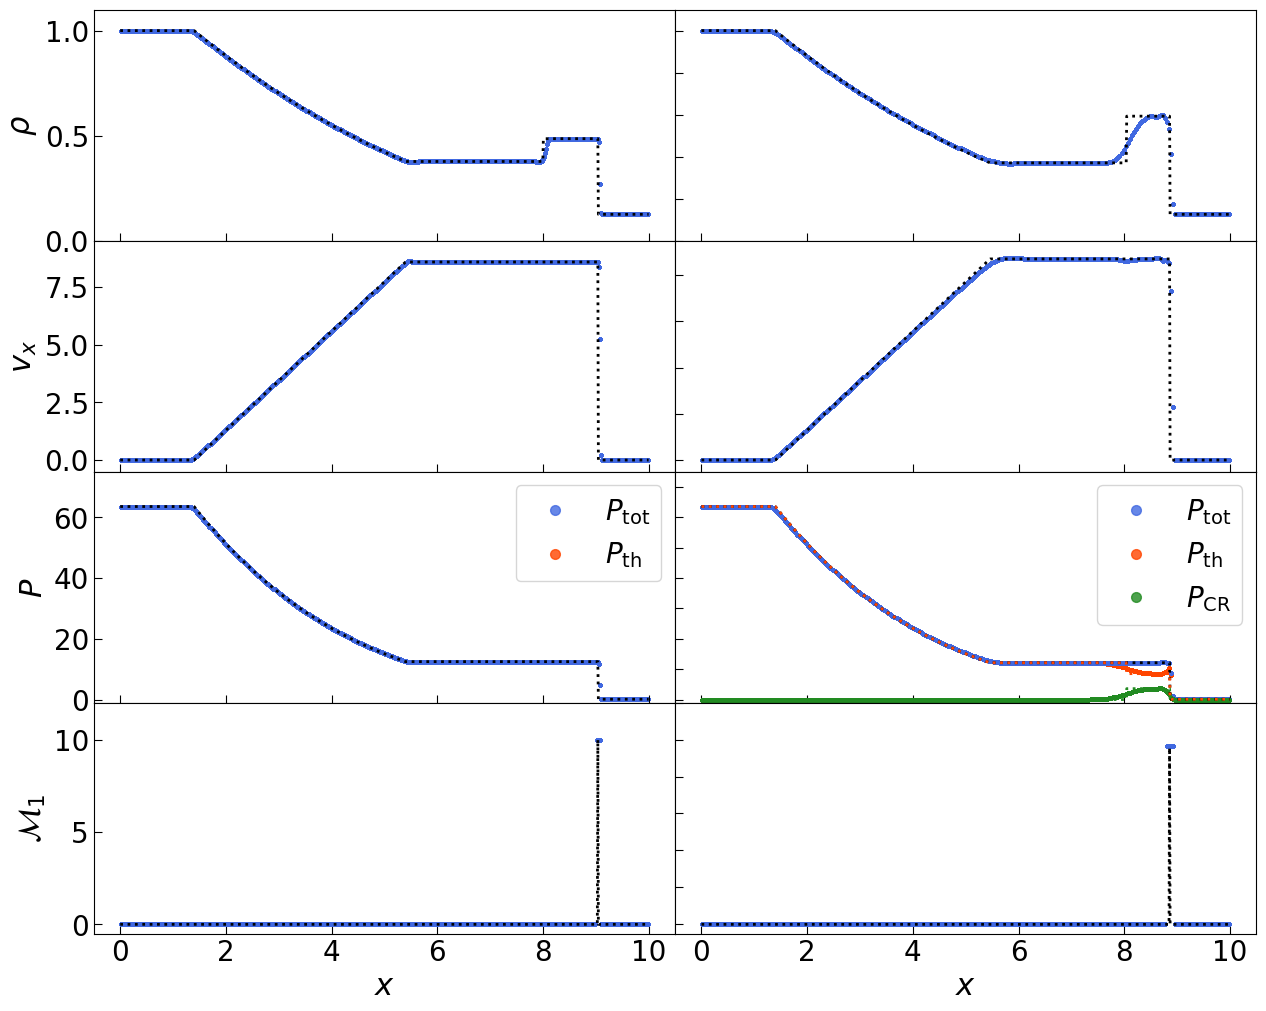

In [9]:
fig = plt.figure(figsize=(15,12))
# fig = plt.figure(figsize=(12,10))
gs = fig.add_gridspec( len(params), len(sim_names), hspace=0, wspace=0)
axs = gs.subplots(sharex=True, sharey=False)

for i, sim_name in enumerate(sim_names):

    for k, param in enumerate(params):

        ax = axs[k] if len(sim_names) == 1 else axs[k,i]
        

        # plot numerical results
        if param == "pres":

            # plot CR and thermal components seperately
            ptot_arr, pth_arr, pcr_arr = sim_params_arr[i][k]

            ax.plot(sim_xcoords_arr[i], ptot_arr, ls="", marker="o", color=pres_colors[0], ms=2.0, mew=1.0, label=r"$P_\mathrm{tot}$", zorder=1, rasterized=True)
            
            ax.plot(sim_xcoords_arr[i], pth_arr, ls="", marker="o", color=pres_colors[1], ms=2.0, mew=1.0, label=r"$P_\mathrm{th}$", zorder=0, rasterized=True)

            if sim_name.find("CR") != -1:
                ax.plot(sim_xcoords_arr[i], pcr_arr, ls="", marker="o", color=pres_colors[2], ms=2.0, mew=1.0, label=r"$P_\mathrm{CR}$", rasterized=True)
        else:
            ax.plot(sim_xcoords_arr[i], sim_params_arr[i][k], ls="", marker="o", color=marker_color, ms=2.0, mew=1.0, alpha=0.9, rasterized=True)

        # plot theoretical results
        ax.plot(xthr_arr + xmid, sim_params_thr_arr[i,k,:], ls=":", color="k", lw=2.0, rasterized=True)

        # if param == "pres" and sim_name.find("CR") != -1:
        #     ax.plot(xthr_arr + xmid, sim_params_pres_arr[0,:], ls=":", color=pres_colors[1], lw=2.0, rasterized=True)
        #     ax.plot(xthr_arr + xmid, sim_params_pres_arr[1,:], ls=":", color=pres_colors[2], lw=2.0, rasterized=True)

        # labels
        ax.set_xlabel("$x$", fontsize=22)
        ax.set_ylabel(param_labels[k], fontsize=22)

        # limits
        ax.set_ylim(param_limits[k])

        # ticks

        # for x
        if k == len(params) - 1:
            ax.tick_params(axis='x', direction="in", which='major', size=6, labelsize=20)
            ax.tick_params(axis='x', direction="in", which='minor', size=4, labelsize=16)
        else:
            ax.tick_params(axis='x', direction="in", which='major', size=6, labelsize=0)
            ax.tick_params(axis='x', direction="in", which='minor', size=4, labelsize=0)

        # for y
        if i == 0:
            ax.tick_params(axis='y', direction="in", which='major', size=6, labelsize=20)
            ax.tick_params(axis='y', direction="in", which='minor', size=4, labelsize=16)
        else:
            ax.tick_params(axis='y', direction="in", which='major', size=6, labelsize=0)
            ax.tick_params(axis='y', direction="in", which='minor', size=4, labelsize=0)

        # legend only for pres
        if param == "pres":
            if sim_name.find("CR") != -1:
                ax.legend(handles=pres_handles, prop={"size":20}, loc="upper right")
            else:
                ax.legend(handles=pres_handles[:2], prop={"size":20}, loc="upper right")

        # if param == "dens" and i == 0:
        #     # annotate time
        #     ax.annotate(f"t = {time:.2f}", xy=(8.75, 0.98), color="k", fontsize=20)

        # if i == 1:
            #  ax.set_yticks()

        # external configurations
        ax.label_outer()   # to ignore labels inside

# fig.savefig(os.path.join("/home/watanabe/Projects/meerkat_bowshocks/figures/sod_crinj", f"CRinj_plot_denspres_t{time:.2f}.pdf"), dpi=300, bbox_inches="tight")